<a href="https://colab.research.google.com/github/Matlosa11/Matlosa_Repository/blob/main/Matlosa_Week6_Assignmenr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:


!pip -q install datasets

from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dataset = load_dataset(
    "electricsheepafrica/africa-synth-mining-equipment-failure-all"
)

split_name = next(iter(dataset))
df = dataset[split_name].to_pandas()

print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (5000, 22)

Available columns:
['record_id', 'equipment_id', 'equipment_type', 'manufacturer', 'model_year', 'mine_type', 'country', 'operating_hours', 'event_date', 'event_type', 'failure_mode', 'component_failed', 'severity', 'downtime_hours', 'repair_cost_usd', 'production_loss_tonnes', 'maintenance_type', 'was_scheduled', 'days_since_last_service', 'oil_analysis_flag', 'vibration_flag', 'temperature_flag']


,record_id,equipment_id,equipment_type,manufacturer,model_year,mine_type,country,operating_hours,event_date,event_type,...,severity,downtime_hours,repair_cost_usd,production_loss_tonnes,maintenance_type,was_scheduled,days_since_last_service,oil_analysis_flag,vibration_flag,temperature_flag
0,EQP-ADB3590D,UNIT-1803,haul_truck,Caterpillar,2008,underground,drc,64584,2022-12-03,breakdown,...,major,17.4,70862.60,1711.0,corrective,False,27,False,False,False
1,EQP-596EE017,UNIT-7964,crusher,Sandvik,2019,open_pit,botswana,19253,2023-08-03,breakdown,...,major,46.3,74513.34,10010.0,corrective,False,57,True,False,False
2,EQP-23341C24,UNIT-6890,pump,Metso,2011,open_pit,south_africa,52894,2020-05-28,breakdown,...,major,10.7,17661.80,580.0,corrective,False,107,False,False,False
3,EQP-D8EF5309,UNIT-4949,loader,Volvo,2019,processing_plant,zambia,18369,2024-11-21,condition_based,...,routine,2.5,2218.70,240.0,predictive,False,23,False,True,False
4,EQP-5A611650,UNIT-4896,excavator,Hitachi,2017,underground,ghana,27901,2022-12-30,condition_based,...,minor,7.7,36773.60,1468.0,predictive,False,57,False,False,False


In [4]:


features = [
    "operating_hours",
    "days_since_last_service",
    "downtime_hours",
    "repair_cost_usd",
    "production_loss_tonnes"
]

missing_columns = [col for col in features if col not in df.columns]

if missing_columns:
    raise ValueError(
        f"Missing columns in dataset: {missing_columns}"
    )

X = df[features].copy()

# Convert selected features to numeric values
for col in features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

# Replace infinite values with missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Remove rows with missing selected feature values
X = X.dropna()

print("Number of records selected:", len(X))
display(X.head())
display(X.describe().round(2))

Number of records selected: 5000


,operating_hours,days_since_last_service,downtime_hours,repair_cost_usd,production_loss_tonnes
0,64584,27,17.4,70862.60,1711.0
1,19253,57,46.3,74513.34,10010.0
2,52894,107,10.7,17661.80,580.0
3,18369,23,2.5,2218.70,240.0
4,27901,57,7.7,36773.60,1468.0


,operating_hours,days_since_last_service,downtime_hours,repair_cost_usd,production_loss_tonnes
count,5000.00,5000.00,5000.00,5000.00,5000.00
mean,33820.15,59.50,11.88,26066.37,1679.09
std,18483.22,58.04,16.79,46087.88,3196.99
min,989.00,1.00,0.80,408.36,19.00
25%,17407.50,17.00,3.00,3998.72,269.00
50%,33299.00,42.00,6.30,9822.81,631.50
75%,49854.75,84.00,14.12,29366.34,1797.50
max,67202.00,365.00,235.90,594743.38,49924.00


In [5]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original feature shape:", X.shape)
print("Scaled feature shape:", X_scaled.shape)
print("\nFirst five scaled records:")
display(pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
).head().round(2))

Original feature shape: (5000, 5)
Scaled feature shape: (5000, 5)

First five scaled records:


,operating_hours,days_since_last_service,downtime_hours,repair_cost_usd,production_loss_tonnes
0,1.66,-0.56,0.33,0.97,0.01
1,-0.79,-0.04,2.05,1.05,2.61
2,1.03,0.82,-0.07,-0.18,-0.34
3,-0.84,-0.63,-0.56,-0.52,-0.45
4,-0.32,-0.04,-0.25,0.23,-0.07


In [6]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []
cluster_range = range(2, 9)

for k in cluster_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

scores_df = pd.DataFrame({
    "Number of clusters": list(cluster_range),
    "Inertia": inertias,
    "Silhouette score": silhouette_scores
})

display(scores_df.round(3))

,Number of clusters,Inertia,Silhouette score
0,2,17061.464,0.644
1,3,13491.423,0.293
2,4,10944.752,0.324
3,5,8734.519,0.333
4,6,7672.971,0.334
5,7,7101.256,0.299
6,8,6606.004,0.302


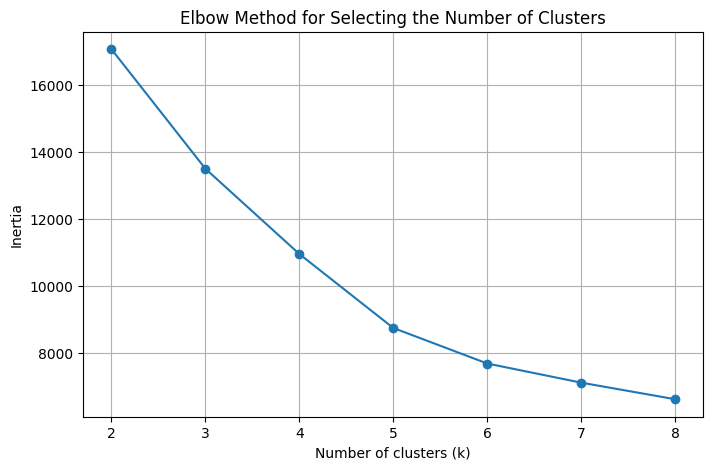

In [7]:

plt.figure(figsize=(8, 5))
plt.plot(
    list(cluster_range),
    inertias,
    marker="o"
)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Selecting the Number of Clusters")
plt.xticks(list(cluster_range))
plt.grid(True)
plt.show()

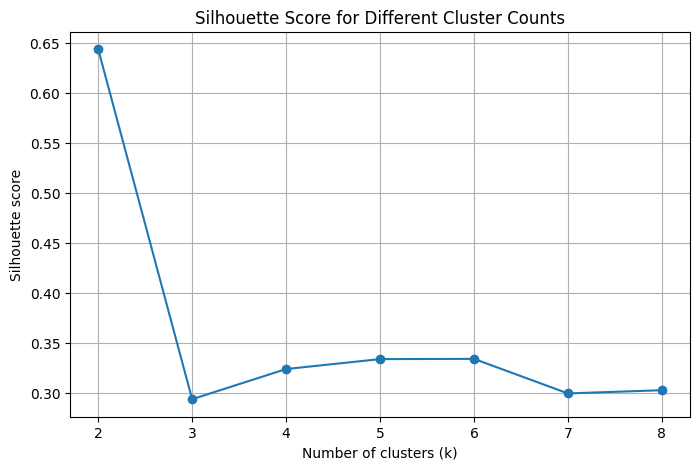

Cluster count with the highest silhouette score: 2


In [8]:

plt.figure(figsize=(8, 5))
plt.plot(
    list(cluster_range),
    silhouette_scores,
    marker="o"
)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score for Different Cluster Counts")
plt.xticks(list(cluster_range))
plt.grid(True)
plt.show()

best_k = list(cluster_range)[
    int(np.argmax(silhouette_scores))
]

print("Cluster count with the highest silhouette score:", best_k)

In [9]:


chosen_k = best_k

final_model = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

cluster_labels = final_model.fit_predict(X_scaled)

clustered_data = X.copy()
clustered_data["Cluster"] = cluster_labels

print("Selected number of clusters:", chosen_k)
print("\nNumber of records in each cluster:")
display(
    clustered_data["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Number of records")
    .to_frame()
)

display(clustered_data.head())

Selected number of clusters: 2

Number of records in each cluster:


,Number of records
Cluster,
0,268
1,4732


,operating_hours,days_since_last_service,downtime_hours,repair_cost_usd,production_loss_tonnes,Cluster
0,64584,27,17.4,70862.60,1711.0,1
1,19253,57,46.3,74513.34,10010.0,0
2,52894,107,10.7,17661.80,580.0,1
3,18369,23,2.5,2218.70,240.0,1
4,27901,57,7.7,36773.60,1468.0,1


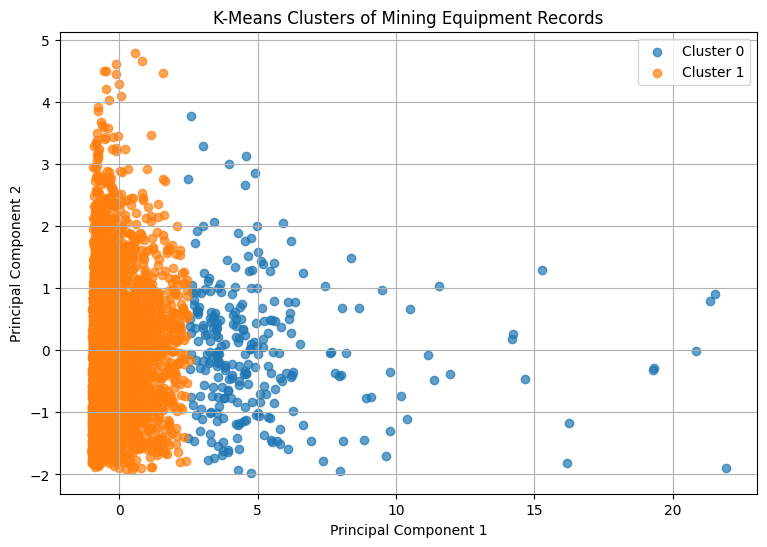

Variance represented by the two components: 73.59 %


In [10]:


from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

for cluster_id in sorted(np.unique(cluster_labels)):
    mask = cluster_labels == cluster_id

    plt.scatter(
        X_2d[mask, 0],
        X_2d[mask, 1],
        label=f"Cluster {cluster_id}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters of Mining Equipment Records")
plt.legend()
plt.grid(True)
plt.show()

print(
    "Variance represented by the two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [11]:


cluster_profiles = (
    clustered_data
    .groupby("Cluster")[features]
    .mean()
    .round(2)
)

print("Average feature values for each cluster:")
display(cluster_profiles)

print("\nMedian feature values for each cluster:")
display(
    clustered_data
    .groupby("Cluster")[features]
    .median()
    .round(2)
)

Average feature values for each cluster:


,operating_hours,days_since_last_service,downtime_hours,repair_cost_usd,production_loss_tonnes
Cluster,,,,,
0,33405.24,65.74,64.71,169165.59,10986.57
1,33843.65,59.14,8.88,17961.85,1151.95



Median feature values for each cluster:


,operating_hours,days_since_last_service,downtime_hours,repair_cost_usd,production_loss_tonnes
Cluster,,,,,
0,33174.5,45.0,56.65,137928.44,9463.0
1,33304.5,41.0,5.70,8929.06,580.5


In [ ]:

## Discussion and Interpretation

K-Means clustering was applied to group mining equipment records using operating hours, days since last service, downtime hours, repair cost, and production loss.

Different numbers of clusters were tested using the Elbow Method and Silhouette Score. Based on the plots, I selected **[insert chosen number] clusters** because **[explain what the plots show]**.

The clustering results identified groups with different feature profiles. Cluster **[insert cluster number]** had relatively high **[insert features supported by your results]**, which may represent equipment records associated with greater maintenance or production impacts. Cluster **[insert cluster number]** had relatively low **[insert features]**, which may represent a lower-impact operating profile. The remaining clusters can be described using their average feature values.

These groupings may help guide further investigation into equipment maintenance and operational performance. However, clustering identifies similarities; it does not establish the causes of breakdowns or production losses.

The dataset is synthetic and is not actual Morupule Coal Mine data. The clusters therefore cannot be treated as confirmed descriptions of real underground mining operations. Future work should use real mine records and include relevant information about continuous miners, shuttle cars, maintenance, geology, equipment position, and approved mining dimensions.